###**Group:**
1. Suha Khalil
2. Sandra Igboabuchukwu
3. Noelle Haviland

##**Large Project 1**
##**Title:** Scalable Diabetes Risk Analytics & Classification using PySpark

##Runtime Calculation Notebook

###Preprocessing runtime:

In [1]:
%pip install pyspark

Note: you may need to restart the kernel to use updated packages.


In [ ]:
#Import Libraries
import pyspark
#import requests
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from pyspark.sql.functions import (
    col,
    sum,
    min,
    max,
    count,
    round as spark_round
)

from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.functions import vector_to_array

#from google.colab import files

import pandas as pd
import matplotlib.pyplot as plt

import time
import os
import psutil
import builtins

In [ ]:
print("Available CPU cores:", os.cpu_count())

print(
    "Total RAM (GB):",
    round(psutil.virtual_memory().total / (1024**3), 2)
)

Available CPU cores: 8
Total RAM (GB): 8.0


In [4]:
SPARK_HOME = "/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark"
SPARK_CLASS = f"{SPARK_HOME}/bin/spark-class"

print("spark-class exists:", os.path.exists(SPARK_CLASS))

spark-class exists: True


In [5]:
#start the Spark Master

import subprocess
import time

master_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1",
        "--port", "7077",
        "--webui-port", "8080"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(3)

print("Master process running:", master_process.poll() is None)

Master process running: True


In [6]:
#start 1 worker with one core
worker_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.worker.Worker",
        "--cores", "1",
        "--memory", "2G",
        "spark://127.0.0.1:7077"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(3)

print("Worker process running:", worker_process.poll() is None)

Worker process running: True


In [7]:
#connect to master /worker
spark = (
    SparkSession.builder
    .appName("DiabetesMLBenchmark")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .getOrCreate()
)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/28 22:52:44 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [8]:
#verify if the standalone setup is active
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)
print("Application ID:", spark.sparkContext.applicationId)

Spark version: 4.2.1
Spark master: spark://127.0.0.1:7077
Default parallelism: 2
Application ID: app-20261028225245-0000


In [9]:
#debugging/verification

import subprocess

result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print(result.stdout)

54547 CoarseGrainedExecutorBackend
54485 Master
54550 Jps
54519 SparkSubmit
54503 Worker



Master → the Spark master

Worker → one worker

SparkSubmit → Spark driver/application

CoarseGrainedExecutorBackend → the executor process launched by that worker

Jps → just the command we used to list Java processes

### **Data Preprocessing**

We must load the data and complete the preprocessing steps before running the machine-learning models. Since this is not my part of the experiment, I will run it here outside of the experiement.

In [10]:
# Upload the file
#uploaded = files.upload()

In [11]:
# 1. Load dataset
#file_path = "/content/diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
file_path = "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

# 2. Validate dimensions
row_count = df.count()
column_count = len(df.columns)

# 3. Check missing values
null_counts = df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

null_counts.collect()   # force Spark to perform the check

# 4. Check exact duplicate rows
distinct_rows = df.distinct().count()
duplicate_rows = row_count - distinct_rows

# 5. Define target and predictors
label_col = "Diabetes_binary"
feature_cols = [
    c for c in df.columns
    if c != label_col
]

# 6. Split into training and test sets
train, test = df.randomSplit(
    [0.8, 0.2],
    seed=42
)

# 7. Assemble predictor features
assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

train_assembled = assembler.transform(train)
test_assembled = assembler.transform(test)

# 8. Fit StandardScaler using training data only
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaledFeatures",
    withStd=True,
    withMean=False
)

scaler_model = scaler.fit(
    train_assembled
)

# 9. Apply scaler to training and test data
train_scaled = scaler_model.transform(
    train_assembled
)

test_scaled = scaler_model.transform(
    test_assembled
)

# Force Spark to execute the final preprocessing pipelines
train_rows = train_scaled.count()
test_rows = test_scaled.count()


26/10/28 22:52:54 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


### **Performance Scaling Experiment**

Each team member will run and time their complete assigned Spark workload using:

**1** executor with 1 core

**2** executors with 1 core each

**4** executors with 1 core each

Each configuration will be repeated at least 3 times.

For each run, we will record:
- Wall-clock runtime
- Number of executors
- Number of partitions
- CPU count
- Available RAM

The mean runtime and standard deviation will be calculated for each configuration.

Speedup will be calculated as:

**Speedup = $T_1 / T_n$**

where $T_1$ is the mean runtime with 1 executor and $T_n$ is the mean runtime with n executors.

### **The warmup time for the machine learning workflow**


26/10/28 22:54:07 WARN BlockManagerMaster: Failed to remove broadcast 2836 with removeFromMaster = true - Block broadcast_2836 does not exist
org.apache.spark.SparkException: Block broadcast_2836 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:309)
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:303)
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:611)
	at org.apache.spark.storage.BlockManager.removeBlockInternal(BlockManager.scala:2190)
	at org.apache.spark.storage.BlockManager.removeBlock(BlockManager.scala:2153)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2(BlockManager.scala:2126)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2$adapted(BlockManager.scala:2126)
	at scala.collection.immutable.List.foreach(List.scala:323)
	at org.apache.spark.storage.BlockManager.removeBroadcast(BlockManager.scala:2126)
	at org.apache.spar

Best elastic net parameter: 0.1
Best regularization parameter: 0.01
Best iterations parameter: 10
                 Predicted Negative  Predicted Positive
Actual Negative             20611.0              7674.0
Actual Positive              6563.0             21634.0
Training Accuracy: 0.7479373959845614
Training Precision: 0.7381602292889313
Training Recall: 0.7672447423484768


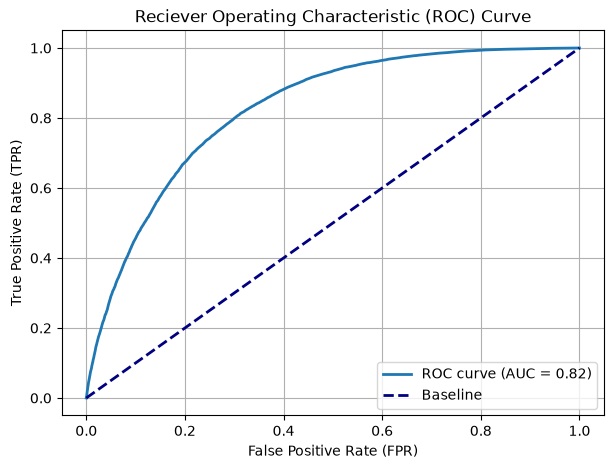

0.824991473201903
                 Predicted Negative  Predicted Positive
Actual Negative              5124.0              1937.0
Actual Positive              1644.0              5505.0
Test Accuracy: 0.7479943701618579
Test Precision: 0.7397205052405268
Test Recall: 0.7700377675199328


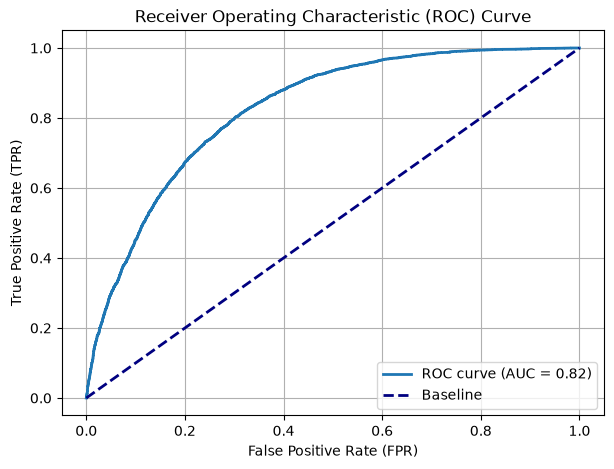

In [ ]:
# Benchmark one complete ML run and allow the SparkSession to "warm up"

# Clear spark cache since preprocessing was also run on spark
spark.catalog.clearCache()

# Begin runtime
start_time = time.perf_counter()

# Tune Logistic Regression model parameters
lr = LogisticRegression(
    family = "binomial",
    featuresCol = "scaledFeatures",
    labelCol = "Diabetes_binary")

# Build parameter grid
paramGrid = (ParamGridBuilder()
            .addGrid(lr.maxIter, [5, 10, 15, 20])
            .addGrid(lr.regParam, [0.1, 0.05, 0.01])
            .addGrid(lr.elasticNetParam, [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
            .build())

# Choose area under ROC curve as evaluation metric for hyperparameter tuning
evaluator = BinaryClassificationEvaluator(metricName = "areaUnderROC", labelCol = "Diabetes_binary")

# Use K-fold cv for model selection
cv = CrossValidator(
    estimator = lr,
    estimatorParamMaps = paramGrid,
    evaluator = evaluator,
    numFolds = 5
)

# Fit the grid on the training data
lrModel = cv.fit(train_scaled)

# Training set ROC curve
training_summary = lrModel.bestModel.summary

# Training set confusion matrix
trainPredictions = lrModel.bestModel.transform(train_scaled)
trainPredictionsAndLabels = trainPredictions.select(
    "prediction", "Diabetes_binary"
).rdd.map(lambda row: (float(row["prediction"]), float(row["Diabetes_binary"])))

train_metrics = MulticlassMetrics(trainPredictionsAndLabels)

train_cm = train_metrics.confusionMatrix().toArray()
train_confusion = pd.DataFrame(
    train_cm,
    index = ["Actual Negative", "Actual Positive"],
    columns = ["Predicted Negative", "Predicted Positive"]
)

# Calculate other training metrics
train_tp = train_cm[1,1]
train_tn = train_cm[0,0]
train_fp = train_cm[0,1]
train_fn = train_cm[1,0]

train_accuracy = (train_tp + train_tn)/(train_tp + train_tn + train_fp + train_fn)
train_precision = (train_tp)/(train_tp + train_fp)
train_recall = (train_tp)/(train_tp + train_fn)

# DataFrame to plot ROC curve
roc_df = training_summary.roc.toPandas()

# Test set
# Make predictions on the test data using the best model
predictions = lrModel.bestModel.transform(test_scaled)

# Test AUC
test_summary = evaluator.evaluate(predictions)

# Test confusion matrix
testPredictionsAndLabels = predictions.select(
    "prediction", "Diabetes_binary"
).rdd.map(lambda row: (float(row["prediction"]), float(row["Diabetes_binary"])))

test_metrics = MulticlassMetrics(testPredictionsAndLabels)

test_cm = test_metrics.confusionMatrix().toArray()
test_confusion = pd.DataFrame(
    test_cm,
    index = ["Actual Negative", "Actual Positive"],
    columns = ["Predicted Negative", "Predicted Positive"]
)

# Other test metrics
test_tp = test_cm[1,1]
test_tn = test_cm[0,0]
test_fp = test_cm[0,1]
test_fn = test_cm[1,0]

test_accuracy = (test_tp + test_tn)/(test_tp + test_tn + test_fp + test_fn)
test_precision = (test_tp)/(test_tp + test_fp)
test_recall = (test_tp)/(test_tp + test_fn)

# Prepare to plot test-set ROC curve
testScoresAndLabels = predictions.select(
    vector_to_array("probability")[1].alias("score"),
    "Diabetes_binary"
).rdd.map(
    lambda row: (float(row["score"]), float(row["Diabetes_binary"]))
)
metrics = testScoresAndLabels.collect()
metrics.sort(key = lambda x: x[0], reverse = True)

import builtins
total_positive = builtins.sum(1 for x in metrics if float(x[1]) == 1.0)
total_negative = len(metrics) - total_positive
tp = 0
fp = 0
fpr = [0.0]
tpr = [0.0]
i = 0

while i < len(metrics):
  threshold = metrics[i][0]
  while i < len(metrics) and metrics[i][0] == threshold:
    if metrics[i][1] == 1.0:
      tp += 1
    else:
      fp += 1
    i += 1
  tpr.append(tp/total_positive)
  fpr.append(fp/total_negative)

# End runtime
end_time = time.perf_counter()

elapsed_time = end_time - start_time


# Print best model hyperparameters
print("Best elastic net parameter:", lrModel.bestModel._java_obj.getElasticNetParam())
print("Best regularization parameter:", lrModel.bestModel._java_obj.getRegParam())
print("Best iterations parameter:", lrModel.bestModel._java_obj.getMaxIter())

# Print training set confusion matrix
print(train_confusion)

# Other training-set metrics
print("Training Accuracy:", train_accuracy)
print("Training Precision:", train_precision)
print("Training Recall:", train_recall)

# Training ROC curve (value)
training_summary.areaUnderROC

# Plot training ROC curve
plt.figure(figsize = (7,5))
plt.plot(roc_df["FPR"], roc_df["TPR"], lw = 2, label = f"ROC curve (AUC = {training_summary.areaUnderROC:.2f})")
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label = "Baseline")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Reciever Operating Characteristic (ROC) Curve")
plt.legend(loc = "lower right")
plt.grid(True)
plt.show()

# Test-set ROC curve
print(test_summary)

# Test-set confusion matrix
print(test_confusion)

# Other test-set metrics
print("Test Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)

# Plot test ROC curve
plt.figure(figsize = (7,5))
plt.plot(fpr, tpr, lw = 2, label = f"ROC curve (AUC = {test_summary:.2f})")
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label = "Baseline")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [ ]:
# Function to measure the runtime for the machine-learning workflow.
# We will call it three times for each executor configuration.

def run_ml_benchmark(num_executors, spark_context, train_scaled, test_scaled):

    # Clear the spark cache
    spark_context.catalog.clearCache()

    start_time = time.perf_counter()

    # Record number of partitions
    num_partitions = spark_context.conf.get("spark.sql.shuffle.partitions")

    # Tune Logistic Regression model parameters
    lr = LogisticRegression(
        family = "binomial",
        featuresCol = "scaledFeatures",
        labelCol = "Diabetes_binary")

    # Build parameter grid
    paramGrid = (ParamGridBuilder()
                .addGrid(lr.maxIter, [5, 10, 15, 20])
                .addGrid(lr.regParam, [0.1, 0.05, 0.01])
                .addGrid(lr.elasticNetParam, [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
                .build())

    # Choose area under ROC curve as evaluation metric for hyperparameter tuning
    evaluator = BinaryClassificationEvaluator(metricName = "areaUnderROC", labelCol = "Diabetes_binary")

    # Use K-fold cv for model selection
    cv = CrossValidator(
        estimator = lr,
        estimatorParamMaps = paramGrid,
        evaluator = evaluator,
        numFolds = 5
    )

    # Fit the grid on the training data
    lrModel = cv.fit(train_scaled)

    # Training set ROC curve
    training_summary = lrModel.bestModel.summary

    # Training set confusion matrix
    trainPredictions = lrModel.bestModel.transform(train_scaled)
    trainPredictionsAndLabels = trainPredictions.select(
        "prediction", "Diabetes_binary"
    ).rdd.map(lambda row: (float(row["prediction"]), float(row["Diabetes_binary"])))

    train_metrics = MulticlassMetrics(trainPredictionsAndLabels)

    train_cm = train_metrics.confusionMatrix().toArray()
    train_confusion = pd.DataFrame(
        train_cm,
        index = ["Actual Negative", "Actual Positive"],
        columns = ["Predicted Negative", "Predicted Positive"]
    )

    # Calculate other training metrics
    train_tp = train_cm[1,1]
    train_tn = train_cm[0,0]
    train_fp = train_cm[0,1]
    train_fn = train_cm[1,0]

    train_accuracy = (train_tp + train_tn)/(train_tp + train_tn + train_fp + train_fn)
    train_precision = (train_tp)/(train_tp + train_fp)
    train_recall = (train_tp)/(train_tp + train_fn)

    # DataFrame to plot ROC curve
    roc_df = training_summary.roc.toPandas()

    # Test set
    # Make predictions on the test data using the best model
    predictions = lrModel.bestModel.transform(test_scaled)

    # Test AUC
    test_summary = evaluator.evaluate(predictions)

    # Test confusion matrix
    testPredictionsAndLabels = predictions.select(
        "prediction", "Diabetes_binary"
    ).rdd.map(lambda row: (float(row["prediction"]), float(row["Diabetes_binary"])))

    test_metrics = MulticlassMetrics(testPredictionsAndLabels)

    test_cm = test_metrics.confusionMatrix().toArray()
    test_confusion = pd.DataFrame(
        test_cm,
        index = ["Actual Negative", "Actual Positive"],
        columns = ["Predicted Negative", "Predicted Positive"]
    )

    # Other test metrics
    test_tp = test_cm[1,1]
    test_tn = test_cm[0,0]
    test_fp = test_cm[0,1]
    test_fn = test_cm[1,0]

    test_accuracy = (test_tp + test_tn)/(test_tp + test_tn + test_fp + test_fn)
    test_precision = (test_tp)/(test_tp + test_fp)
    test_recall = (test_tp)/(test_tp + test_fn)

    # Prepare to plot test-set ROC curve
    testScoresAndLabels = predictions.select(
        vector_to_array("probability")[1].alias("score"),
        "Diabetes_binary"
    ).rdd.map(
        lambda row: (float(row["score"]), float(row["Diabetes_binary"]))
    )
    metrics = testScoresAndLabels.collect()
    metrics.sort(key = lambda x: x[0], reverse = True)

    import builtins
    total_positive = builtins.sum(1 for x in metrics if float(x[1]) == 1.0)
    total_negative = len(metrics) - total_positive
    tp = 0
    fp = 0
    fpr = [0.0]
    tpr = [0.0]
    i = 0

    while i < len(metrics):
      threshold = metrics[i][0]
      while i < len(metrics) and metrics[i][0] == threshold:
        if metrics[i][1] == 1.0:
          tp += 1
        else:
          fp += 1
        i += 1
      tpr.append(tp/total_positive)
      fpr.append(fp/total_negative)

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    # System information
    cpu_count = os.cpu_count()
    available_ram_gb = psutil.virtual_memory().available / (1024**3)
    total_ram = psutil.virtual_memory().total / (1024**3)

    return {
        "Executors": num_executors,
        "Runtime_seconds": elapsed_time,
        "Partitions": num_partitions,
        "CPU_count": cpu_count,
        "Available_RAM_GB": available_ram_gb,
        "Total_RAM_GB": total_ram
    }

In [15]:
results_1_executor = []

for run in range(1, 4):

    result = run_ml_benchmark(num_executors=1, spark_context = spark, train_scaled = train_scaled, test_scaled = test_scaled)

    result["Run"] = run
    results_1_executor.append(result)

    print(
        f"Run {run}: "
        f"{result['Runtime_seconds']:.3f} seconds"
    )

26/10/28 23:01:50 WARN BlockManagerMaster: Failed to remove broadcast 28154 with removeFromMaster = true - Block broadcast_28154 does not exist
org.apache.spark.SparkException: Block broadcast_28154 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:309)
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:303)
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:611)
	at org.apache.spark.storage.BlockManager.removeBlockInternal(BlockManager.scala:2190)
	at org.apache.spark.storage.BlockManager.removeBlock(BlockManager.scala:2153)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2(BlockManager.scala:2126)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2$adapted(BlockManager.scala:2126)
	at scala.collection.immutable.List.foreach(List.scala:323)
	at org.apache.spark.storage.BlockManager.removeBroadcast(BlockManager.scala:2126)
	at org.apache.s

Run 1: 470.741 seconds


/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


Run 2: 462.575 seconds


26/10/28 23:17:48 WARN BlockManagerMaster: Failed to remove broadcast 84886 with removeFromMaster = true - Block broadcast_84886 does not exist
org.apache.spark.SparkException: Block broadcast_84886 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:309)
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:303)
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:611)
	at org.apache.spark.storage.BlockManager.removeBlockInternal(BlockManager.scala:2190)
	at org.apache.spark.storage.BlockManager.removeBlock(BlockManager.scala:2153)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2(BlockManager.scala:2126)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2$adapted(BlockManager.scala:2126)
	at scala.collection.immutable.List.foreach(List.scala:323)
	at org.apache.spark.storage.BlockManager.removeBroadcast(BlockManager.scala:2126)
	at org.apache.s

Run 3: 459.758 seconds


In [16]:
#Create a table for the results

results_1_df = pd.DataFrame(results_1_executor)

results_1_df = results_1_df[
    [
        "Run",
        "Executors",
        "Runtime_seconds",
        "Partitions",
        "CPU_count",
        "Available_RAM_GB"
    ]
]

results_1_df

,Run,Executors,Runtime_seconds,Partitions,CPU_count,Available_RAM_GB
0,1,1,470.741349,200,8,1.426773
1,2,1,462.574900,200,8,1.360306
2,3,1,459.758121,200,8,1.384995


In [17]:
mean_runtime_1 = results_1_df["Runtime_seconds"].mean()
std_runtime_1 = results_1_df["Runtime_seconds"].std()

print(f"Mean runtime: {mean_runtime_1:.3f} seconds")
print(f"Standard deviation: {std_runtime_1:.3f} seconds")

Mean runtime: 464.358 seconds
Standard deviation: 5.705 seconds


##Repeat the experiment with two executors, 1 core each , but first we should stop the current spark application with 1 executor.

In [18]:
# stop spark application
try:
    spark.stop()
    print("Spark application stopped.")
except Exception as e:
    print("No active Spark application or it was already stopped.")

Spark application stopped.


In [19]:
# this is a cleanup loop that makes sure the old master and worker are stopped

import subprocess
import os
import signal
import time

result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print("Before cleanup:")
print(result.stdout)

for line in result.stdout.strip().splitlines():
    parts = line.split()

    # Skip warning lines or anything that does not start with a numeric PID
    if len(parts) >= 2 and parts[0].isdigit():

        pid = int(parts[0])
        process_name = parts[1]

        if process_name in ["Master", "Worker"]:
            print(f"Stopping {process_name} PID {pid}")
            os.kill(pid, signal.SIGTERM)

time.sleep(3)

Before cleanup:
54834 Jps
54485 Master
54519 SparkSubmit
54503 Worker

Stopping Master PID 54485
Stopping Worker PID 54503


In [20]:
# make sure they stopped :
result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print(result.stdout)

54836 Jps
54519 SparkSubmit



In [21]:
# Start a fresh Spark Master for the 2-executor experiment

master_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1",
        "--port", "7077",
        "--webui-port", "8080"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(3)

print("Master process running:", master_process.poll() is None)

Master process running: True


In [22]:
# Start 2 Spark workers, each with 1 core

#create an empty list to save the workers after we create them
worker_processes = []

#create workers, I assigned a different port number for each worker :
for i in range(2):
    worker = subprocess.Popen(
        [
            SPARK_CLASS,
            "org.apache.spark.deploy.worker.Worker",
            "--cores", "1",
            "--memory", "2G",
            "--webui-port", str(8081 + i),
            "spark://127.0.0.1:7077"
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    worker_processes.append(worker)

time.sleep(4)

for i, worker in enumerate(worker_processes, start=1):
    print(f"Worker {i} running:", worker.poll() is None)

Worker 1 running: True
Worker 2 running: True


In [23]:
# reconnect Spark application to use these two 1-core workers we created :
spark2 = (
    SparkSession.builder
    .appName("DiabetesML2")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.executor.instances", "2")
    .config("spark.dynamicAllocation.enabled", "false")
    .config("spark.cores.max", "2")
    .getOrCreate()
)

print("Spark master:", spark2.sparkContext.master)
print("Application ID:", spark2.sparkContext.applicationId)

Spark master: spark://127.0.0.1:7077
Application ID: app-20261028232504-0000


In [24]:
#Verify the Java Process :
result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print(result.stdout)

54880 CoarseGrainedExecutorBackend
54881 CoarseGrainedExecutorBackend
54882 Jps
54837 Master
54854 Worker
54519 SparkSubmit
54855 Worker



In [25]:
# 1. Load dataset
#file_path = "/content/diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
file_path = "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

df2 = spark2.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

# 2. Validate dimensions
row_count2 = df2.count()
column_count2 = len(df2.columns)

# 3. Check missing values
null_counts2 = df2.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df2.columns
])

null_counts2.collect()   # force Spark to perform the check

# 4. Check exact duplicate rows
distinct_rows2 = df2.distinct().count()
duplicate_rows2 = row_count2 - distinct_rows2

# 5. Define target and predictors
label_col = "Diabetes_binary"
feature_cols = [
    c for c in df2.columns
    if c != label_col
]

# 6. Split into training and test sets
train2, test2 = df2.randomSplit(
    [0.8, 0.2],
    seed=42
)

# 7. Assemble predictor features
assembler2 = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

train_assembled2 = assembler2.transform(train2)
test_assembled2 = assembler2.transform(test2)

# 8. Fit StandardScaler using training data only
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaledFeatures",
    withStd=True,
    withMean=False
)

scaler_model = scaler.fit(
    train_assembled2
)

# 9. Apply scaler to training and test data
train_scaled2 = scaler_model.transform(
    train_assembled2
)

test_scaled2 = scaler_model.transform(
    test_assembled2
)

# Force Spark to execute the final preprocessing pipelines
train_rows2 = train_scaled2.count()
test_rows2 = test_scaled2.count()


In [26]:
warmup_2 = run_ml_benchmark(num_executors=2, spark_context = spark2, train_scaled = train_scaled2, test_scaled = test_scaled2)

print(f"2-executor warm-up runtime: {warmup_2['Runtime_seconds']:.3f} seconds")

26/10/28 23:25:52 WARN BlockManagerMaster: Failed to remove broadcast 1792 with removeFromMaster = true - Block broadcast_1792 does not exist
org.apache.spark.SparkException: Block broadcast_1792 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:309)
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:303)
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:611)
	at org.apache.spark.storage.BlockManager.removeBlockInternal(BlockManager.scala:2190)
	at org.apache.spark.storage.BlockManager.removeBlock(BlockManager.scala:2153)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2(BlockManager.scala:2126)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2$adapted(BlockManager.scala:2126)
	at scala.collection.immutable.List.foreach(List.scala:323)
	at org.apache.spark.storage.BlockManager.removeBroadcast(BlockManager.scala:2126)
	at org.apache.spar

2-executor warm-up runtime: 422.870 seconds


In [28]:
results_2_executor = []

for run in range(1, 4):

    result = run_ml_benchmark(num_executors=2, spark_context = spark2, train_scaled = train_scaled2, test_scaled = test_scaled2)

    result["Run"] = run
    results_2_executor.append(result)

    print(
        f"Run {run}: "
        f"{result['Runtime_seconds']:.3f} seconds"
    )

/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(
/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/opt/homebrew/ana

Run 1: 397.390 seconds


26/10/28 23:41:27 ERROR ContextCleaner: Error cleaning broadcast 64058
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:70)
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:44)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.storage.BlockManagerMaster.removeBroadcast(BlockManagerMaster.scala:228)
	at org.apache.spark.broadcast.TorrentBroadcast$.unpersist(TorrentBroadcast.scala:399)
	at org.apache.spark.broadcast.TorrentBroadcastFactory.unbroadcast(TorrentBroadcastFactory.scala:49)
	at org.apache.spark.broadcast.BroadcastManager.unbroadcast(BroadcastManager.scala:82)
	at org.apache.spark.ContextCleaner.doCleanupBroadcast(ContextCleaner.scala:257)
	at org.apache.spark.ContextCleaner.$anonfun$keepCleaning$3(ContextCleaner.scala:205)
	at org.apache.sp

Run 2: 394.561 seconds


26/10/28 23:46:16 WARN BlockManagerMaster: Failed to remove broadcast 84020 with removeFromMaster = true - Block broadcast_84020 does not exist
org.apache.spark.SparkException: Block broadcast_84020 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:309)
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:303)
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:611)
	at org.apache.spark.storage.BlockManager.removeBlockInternal(BlockManager.scala:2190)
	at org.apache.spark.storage.BlockManager.removeBlock(BlockManager.scala:2153)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2(BlockManager.scala:2126)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2$adapted(BlockManager.scala:2126)
	at scala.collection.immutable.List.foreach(List.scala:323)
	at org.apache.spark.storage.BlockManager.removeBroadcast(BlockManager.scala:2126)
	at org.apache.s

Run 3: 398.419 seconds


In [53]:
results_2_df = pd.DataFrame(results_2_executor)

results_2_df = results_2_df[
    [
        "Run",
        "Executors",
        "Runtime_seconds",
        "Partitions",
        "CPU_count",
        "Available_RAM_GB",
    ]
]

results_2_df

,Run,Executors,Runtime_seconds,Partitions,CPU_count,Available_RAM_GB
0,1,2,397.389969,200,8,1.407776
1,2,2,394.561155,200,8,1.409119
2,3,2,398.418961,200,8,1.273254


In [30]:
mean_runtime_2 = results_2_df["Runtime_seconds"].mean()
std_runtime_2 = results_2_df["Runtime_seconds"].std()

print(f"Mean runtime: {mean_runtime_2:.3f} seconds")
print(f"Standard deviation: {std_runtime_2:.3f} seconds")

Mean runtime: 396.790 seconds
Standard deviation: 1.998 seconds


In [31]:
#before I move to 4 executors, I will compare the two experiemnes with 1 and 2 executors

comparison_df = pd.DataFrame({
    "Executors": [1, 2],
    "Mean_Runtime_s": [
        results_1_df["Runtime_seconds"].mean(),
        results_2_df["Runtime_seconds"].mean()
    ],
    "Std_Runtime_s": [
        results_1_df["Runtime_seconds"].std(),
        results_2_df["Runtime_seconds"].std()
    ]
})

comparison_df["Speedup"] = (
    comparison_df.loc[comparison_df["Executors"] == 1, "Mean_Runtime_s"].iloc[0]
    / comparison_df["Mean_Runtime_s"]
)

comparison_df

,Executors,Mean_Runtime_s,Std_Runtime_s,Speedup
0,1,464.358123,5.704625,1.000000
1,2,396.790028,1.997652,1.170287


### Runtime plot

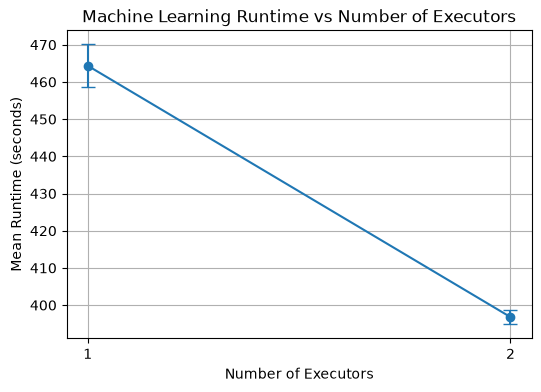

In [33]:
plt.figure(figsize=(6,4))

plt.errorbar(
    comparison_df["Executors"],
    comparison_df["Mean_Runtime_s"],
    yerr=comparison_df["Std_Runtime_s"],
    marker="o",
    capsize=5
)

plt.xlabel("Number of Executors")
plt.ylabel("Mean Runtime (seconds)")
plt.title("Machine Learning Runtime vs Number of Executors")
plt.xticks([1, 2])
plt.grid(True)
plt.show()

### Speed up plot

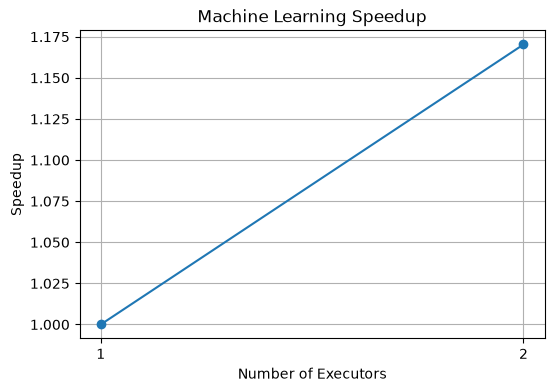

In [34]:
plt.figure(figsize=(6,4))

plt.plot(
    comparison_df["Executors"],
    comparison_df["Speedup"],
    marker="o"
)

plt.xlabel("Number of Executors")
plt.ylabel("Speedup")
plt.title("Machine Learning Speedup")
plt.xticks([1, 2])
plt.grid(True)
plt.show()

The 2-executor configuration did not improve preprocessing performance. Its mean runtime was slightly higher than the 1-executor configuration, producing a speedup below 1. However, the relatively large run-to-run variability suggests that the difference is small compared with normal execution variation.

##Repeat the experiment with four executors, one core each

In [35]:
# stop spark application
try:
    spark2.stop()
    print("Spark application stopped.")
except Exception as e:
    print("No active Spark application or it was already stopped.")

Spark application stopped.


In [36]:
# this is a cleanup loop that makes sure the old master and worker are stopped

import subprocess
import os
import signal
import time

result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print("Before cleanup:")
print(result.stdout)

for line in result.stdout.strip().splitlines():
    parts = line.split()

    # Skip warning lines or anything that does not start with a numeric PID
    if len(parts) >= 2 and parts[0].isdigit():

        pid = int(parts[0])
        process_name = parts[1]

        if process_name in ["Master", "Worker"]:
            print(f"Stopping {process_name} PID {pid}")
            os.kill(pid, signal.SIGTERM)

time.sleep(3)

Before cleanup:
55024 Jps
54837 Master
54854 Worker
54519 SparkSubmit
54855 Worker

Stopping Master PID 54837
Stopping Worker PID 54854
Stopping Worker PID 54855


In [37]:
# make sure they stopped :
result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print(result.stdout)

55027 Jps
54519 SparkSubmit



In [38]:
# Start a fresh Spark Master for the 4-executor experiment

master_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1",
        "--port", "7077",
        "--webui-port", "8080"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

time.sleep(3)

print("Master process running:", master_process.poll() is None)

Master process running: True


In [39]:
# Start 4 Spark workers, each with 1 core

#create an empty list to save the workers after we create them
worker_processes_4 = []

#create workers, I assigned a different port number for each worker :
for i in range(4):
    worker = subprocess.Popen(
        [
            SPARK_CLASS,
            "org.apache.spark.deploy.worker.Worker",
            "--cores", "1",
            "--memory", "2G",
            "--webui-port", str(8081 + i),
            "spark://127.0.0.1:7077"
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE
    )

    worker_processes_4.append(worker)

time.sleep(6)

for i, worker in enumerate(worker_processes_4, start=1):
    print(f"Worker {i} running:", worker.poll() is None)

Worker 1 running: True
Worker 2 running: True
Worker 3 running: True
Worker 4 running: True


In [40]:
# reconnect Spark application to use these four 1-core workers we created :
spark4 = (
    SparkSession.builder
    .appName("DiabetesML4")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.executor.instances", "4")
    .config("spark.dynamicAllocation.enabled", "false")
    .config("spark.cores.max", "4")
    .getOrCreate()
)

print("Spark master:", spark4.sparkContext.master)
print("Application ID:", spark4.sparkContext.applicationId)

Spark master: spark://127.0.0.1:7077
Application ID: app-20261028235413-0000


In [41]:
#Verify the Java Process :
result = subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
)

print(result.stdout)

55108 Jps
55028 Master
55045 Worker
55046 Worker
54519 SparkSubmit
55047 Worker
55049 Worker
55099 CoarseGrainedExecutorBackend
55100 CoarseGrainedExecutorBackend
55101 CoarseGrainedExecutorBackend
55102 CoarseGrainedExecutorBackend



In [42]:
# 1. Load dataset
#file_path = "/content/diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
file_path = "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

df4 = spark4.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

# 2. Validate dimensions
row_count4 = df4.count()
column_count4 = len(df4.columns)

# 3. Check missing values
null_counts4 = df4.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df4.columns
])

null_counts4.collect()   # force Spark to perform the check

# 4. Check exact duplicate rows
distinct_rows4 = df4.distinct().count()
duplicate_rows4 = row_count4 - distinct_rows4

# 5. Define target and predictors
label_col = "Diabetes_binary"
feature_cols = [
    c for c in df4.columns
    if c != label_col
]

# 6. Split into training and test sets
train4, test4 = df4.randomSplit(
    [0.8, 0.2],
    seed=42
)

# 7. Assemble predictor features
assembler4 = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

train_assembled4 = assembler4.transform(train4)
test_assembled4 = assembler4.transform(test4)

# 8. Fit StandardScaler using training data only
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaledFeatures",
    withStd=True,
    withMean=False
)

scaler_model = scaler.fit(
    train_assembled4
)

# 9. Apply scaler to training and test data
train_scaled4 = scaler_model.transform(
    train_assembled4
)

test_scaled4 = scaler_model.transform(
    test_assembled4
)

# Force Spark to execute the final preprocessing pipelines
train_rows4 = train_scaled4.count()
test_rows4= test_scaled4.count()

In [43]:
warmup_4 = run_ml_benchmark(num_executors=4, spark_context = spark4, train_scaled = train_scaled4, test_scaled = test_scaled4)

print(f"4-executor warm-up runtime: {warmup_4['Runtime_seconds']:.3f} seconds")

26/10/29 00:01:11 WARN BlockManagerMaster: Failed to remove broadcast 18020 with removeFromMaster = true - Block broadcast_18020 does not exist
org.apache.spark.SparkException: Block broadcast_18020 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:309)
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:303)
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:611)
	at org.apache.spark.storage.BlockManager.removeBlockInternal(BlockManager.scala:2190)
	at org.apache.spark.storage.BlockManager.removeBlock(BlockManager.scala:2153)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2(BlockManager.scala:2126)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2$adapted(BlockManager.scala:2126)
	at scala.collection.immutable.List.foreach(List.scala:323)
	at org.apache.spark.storage.BlockManager.removeBroadcast(BlockManager.scala:2126)
	at org.apache.s

4-executor warm-up runtime: 530.707 seconds


In [44]:
results_4_executor = []

for run in range(1, 4):

    result = run_ml_benchmark(num_executors=4, spark_context = spark4, train_scaled = train_scaled4, test_scaled = test_scaled4)

    result["Run"] = run
    results_4_executor.append(result)

    print(
        f"Run {run}: "
        f"{result['Runtime_seconds']:.3f} seconds"
    )

26/10/29 00:05:24 WARN BlockManagerMaster: Failed to remove broadcast 30393 with removeFromMaster = true - Block broadcast_30393 does not exist
org.apache.spark.SparkException: Block broadcast_30393 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:309)
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:303)
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:611)
	at org.apache.spark.storage.BlockManager.removeBlockInternal(BlockManager.scala:2190)
	at org.apache.spark.storage.BlockManager.removeBlock(BlockManager.scala:2153)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2(BlockManager.scala:2126)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2$adapted(BlockManager.scala:2126)
	at scala.collection.immutable.List.foreach(List.scala:323)
	at org.apache.spark.storage.BlockManager.removeBroadcast(BlockManager.scala:2126)
	at org.apache.s

Run 1: 458.963 seconds


26/10/29 00:15:27 WARN BlockManagerMaster: Failed to remove broadcast 66894 with removeFromMaster = true - Block broadcast_66894 does not exist
org.apache.spark.SparkException: Block broadcast_66894 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:309)
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:303)
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:611)
	at org.apache.spark.storage.BlockManager.removeBlockInternal(BlockManager.scala:2190)
	at org.apache.spark.storage.BlockManager.removeBlock(BlockManager.scala:2153)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2(BlockManager.scala:2126)
	at org.apache.spark.storage.BlockManager.$anonfun$removeBroadcast$2$adapted(BlockManager.scala:2126)
	at scala.collection.immutable.List.foreach(List.scala:323)
	at org.apache.spark.storage.BlockManager.removeBroadcast(BlockManager.scala:2126)
	at org.apache.s

Run 2: 473.688 seconds


/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/opt/homebrew/anaconda3/envs/sat5165-experiment/lib/python3.12/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


Run 3: 409.635 seconds


In [45]:
results_4_df = pd.DataFrame(results_4_executor)

results_4_df = results_4_df[
    [
        "Run",
        "Executors",
        "Runtime_seconds",
        "Partitions",
        "CPU_count",
        "Available_RAM_GB"
    ]
]

results_4_df

,Run,Executors,Runtime_seconds,Partitions,CPU_count,Available_RAM_GB
0,1,4,458.963468,200,8,1.332092
1,2,4,473.688267,200,8,1.248917
2,3,4,409.634551,200,8,1.261719


In [46]:
mean_runtime_4 = results_4_df["Runtime_seconds"].mean()
std_runtime_4 = results_4_df["Runtime_seconds"].std()

print(f"Mean runtime: {mean_runtime_4:.3f} seconds")
print(f"Standard deviation: {std_runtime_4:.3f} seconds")

Mean runtime: 447.429 seconds
Standard deviation: 33.549 seconds


In [47]:
full_comparison_df = pd.DataFrame({
    "Executors": [1, 2, 4],
    "Mean_Runtime_s": [
        results_1_df["Runtime_seconds"].mean(),
        results_2_df["Runtime_seconds"].mean(),
        results_4_df["Runtime_seconds"].mean()
    ],
    "Std_Runtime_s": [
        results_1_df["Runtime_seconds"].std(),
        results_2_df["Runtime_seconds"].std(),
        results_4_df["Runtime_seconds"].std()
    ]
})

baseline_runtime = full_comparison_df.loc[
    full_comparison_df["Executors"] == 1,
    "Mean_Runtime_s"
].iloc[0]

full_comparison_df["Speedup"] = (
    baseline_runtime / full_comparison_df["Mean_Runtime_s"]
)

full_comparison_df

,Executors,Mean_Runtime_s,Std_Runtime_s,Speedup
0,1,464.358123,5.704625,1.000000
1,2,396.790028,1.997652,1.170287
2,4,447.428762,33.548573,1.037837


## Runtime plot

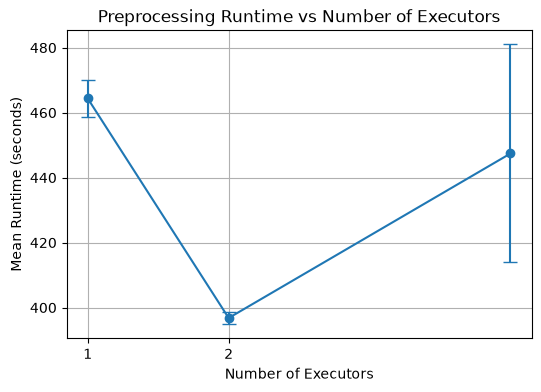

In [48]:
plt.figure(figsize=(6,4))

plt.errorbar(
    full_comparison_df["Executors"],
    full_comparison_df["Mean_Runtime_s"],
    yerr=full_comparison_df["Std_Runtime_s"],
    marker="o",
    capsize=5
)

plt.xlabel("Number of Executors")
plt.ylabel("Mean Runtime (seconds)")
plt.title("Preprocessing Runtime vs Number of Executors")
plt.xticks([1, 2])
plt.grid(True)
plt.show()

## Speed-up plot

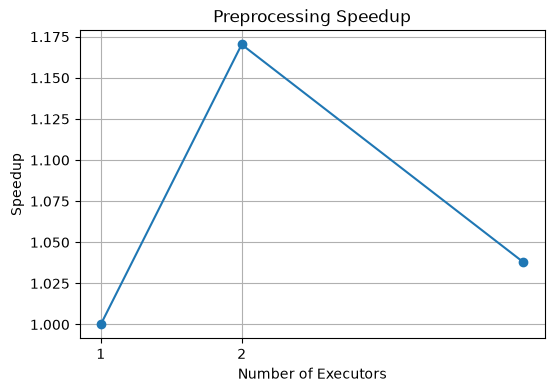

26/10/29 00:50:48 WARN HeartbeatReceiver: Removing executor 0 with no recent heartbeats: 460326 ms exceeds timeout 120000 ms
26/10/29 00:50:48 WARN HeartbeatReceiver: Removing executor 1 with no recent heartbeats: 461331 ms exceeds timeout 120000 ms
26/10/29 00:50:48 WARN HeartbeatReceiver: Removing executor 2 with no recent heartbeats: 461199 ms exceeds timeout 120000 ms
26/10/29 00:50:48 WARN HeartbeatReceiver: Removing executor 3 with no recent heartbeats: 459508 ms exceeds timeout 120000 ms
26/10/29 00:50:48 ERROR TaskSchedulerImpl: Lost executor 0 on 141.219.222.159: Executor heartbeat timed out after 460326 ms
26/10/29 00:50:48 ERROR TaskSchedulerImpl: Lost executor 1 on 141.219.222.159: Executor heartbeat timed out after 461331 ms
26/10/29 00:50:48 ERROR TaskSchedulerImpl: Lost executor 2 on 141.219.222.159: Executor heartbeat timed out after 461199 ms
26/10/29 00:50:48 ERROR TaskSchedulerImpl: Lost executor 3 on 141.219.222.159: Executor heartbeat timed out after 459508 ms
26/1

In [49]:
plt.figure(figsize=(6,4))

plt.plot(
    full_comparison_df["Executors"],
    full_comparison_df["Speedup"],
    marker="o"
)

plt.xlabel("Number of Executors")
plt.ylabel("Speedup")
plt.title("Preprocessing Speedup")
plt.xticks([1, 2])
plt.grid(True)
plt.show()

In [51]:
# Get total RAM
print(psutil.virtual_memory().total / (1024 ** 3))

8.0
